In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
housing = fetch_california_housing(as_frame=True)

df = housing.frame.copy()
target_column = "MedHouseVal"

print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [17]:
df.shape

(20640, 9)

In [19]:
df.duplicated().sum()

np.int64(0)

Columns:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']
\nData types:


,Data type
MedInc,float64
HouseAge,float64
AveRooms,float64
AveBedrms,float64
Population,float64
AveOccup,float64
Latitude,float64
Longitude,float64
MedHouseVal,float64


\nSummary statistics:


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


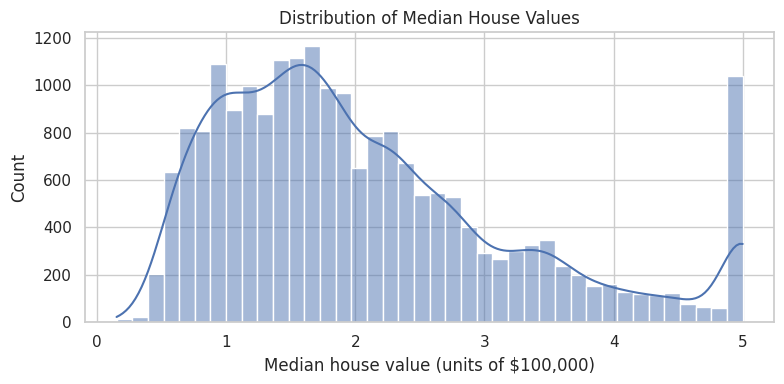

In [3]:
print("Columns:")
print(df.columns.tolist())

print("\\nData types:")
display(df.dtypes.to_frame("Data type"))

print("\\nSummary statistics:")
display(df.describe().T)

plt.figure(figsize=(8, 4))
sns.histplot(df[target_column], bins=40, kde=True)
plt.title("Distribution of Median House Values")
plt.xlabel("Median house value (units of $100,000)")
plt.tight_layout()
plt.show()

In [4]:
X_raw = df.drop(columns=[target_column]).copy()
y = df[target_column].copy()

missing_counts = X_raw.isna().sum().sort_values(ascending=False)
print("Missing values per input feature:")
display(missing_counts.to_frame("Missing count"))

print("Total missing input values:", int(X_raw.isna().sum().sum()))
print("Missing target values:", int(y.isna().sum()))

# Remove rows only if the target itself is missing; input missing values are imputed later.
valid_target = y.notna()
X_raw = X_raw.loc[valid_target].copy()
y = y.loc[valid_target].copy()

Missing values per input feature:


,Missing count
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0


Total missing input values: 0
Missing target values: 0


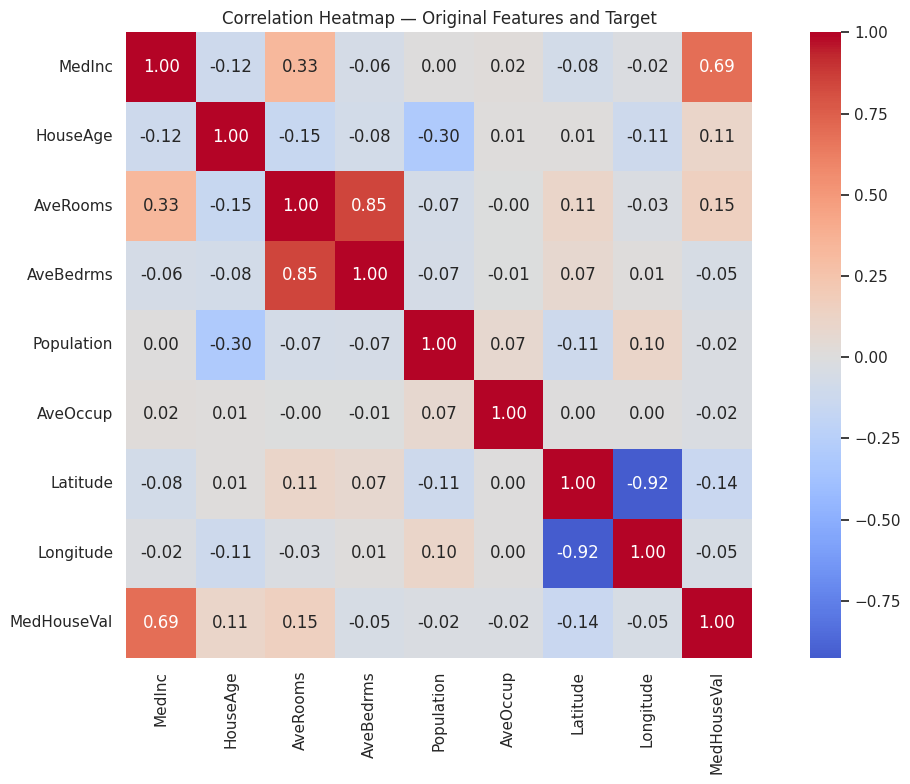

Features most correlated with the target (by absolute correlation):


,Correlation with target
MedInc,0.688075
AveRooms,0.151948
Latitude,-0.144160
HouseAge,0.105623
AveBedrms,-0.046701
Longitude,-0.045967
Population,-0.024650
AveOccup,-0.023737


In [5]:
plt.figure(figsize=(12, 8))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap — Original Features and Target")
plt.tight_layout()
plt.show()

target_corr = corr[target_column].drop(target_column).sort_values(key=np.abs, ascending=False)
print("Features most correlated with the target (by absolute correlation):")
display(target_corr.to_frame("Correlation with target"))

Original feature count: 8
Feature count after interactions: 11


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedInc_x_AveRooms,MedInc_x_Latitude,HouseAge_x_AveRooms
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,58.144254,315.358576,286.349206
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,51.785271,314.291004,131.000879
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,60.150315,274.692590,430.983051
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,32.827897,213.591335,302.502283
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,24.161264,145.578670,326.656371


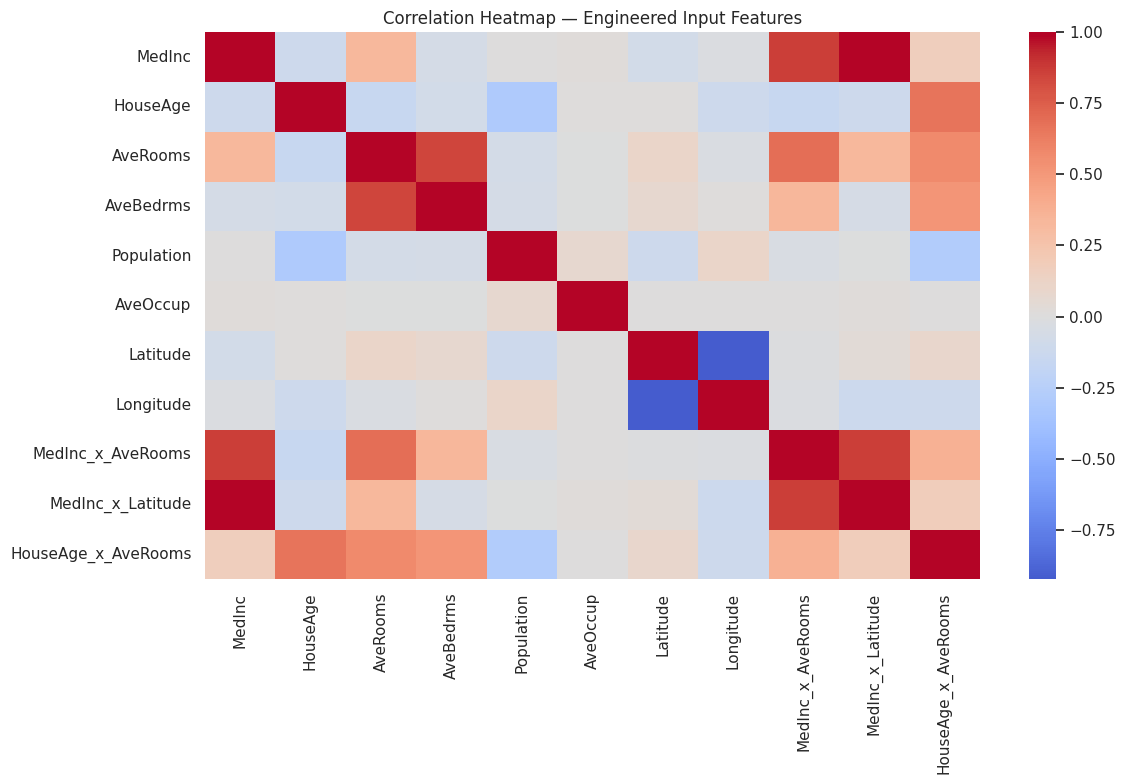

In [6]:
def add_interaction_features(X):
    X = X.copy()
    X["MedInc_x_AveRooms"] = X["MedInc"] * X["AveRooms"]
    X["MedInc_x_Latitude"] = X["MedInc"] * X["Latitude"]
    X["HouseAge_x_AveRooms"] = X["HouseAge"] * X["AveRooms"]
    return X

X = add_interaction_features(X_raw)

print("Original feature count:", X_raw.shape[1])
print("Feature count after interactions:", X.shape[1])
display(X.head())

plt.figure(figsize=(12, 8))
sns.heatmap(X.corr(numeric_only=True), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap — Engineered Input Features")
plt.tight_layout()
plt.show()

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training input shape: (16512, 11)
Testing input shape: (4128, 11)
Training target shape: (16512,)
Testing target shape: (4128,)


In [8]:
def make_pipeline(regressor):
    return Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", regressor)
    ])

print("Preprocessing pipeline defined: median imputation -> standardization -> regression model.")

Preprocessing pipeline defined: median imputation -> standardization -> regression model.


In [9]:
ols_pipeline = make_pipeline(LinearRegression())
ols_pipeline.fit(X_train, y_train)

ols_predictions = ols_pipeline.predict(X_test)
print("OLS model trained.")
print("First 10 predictions:", np.round(ols_predictions[:10], 3))

OLS model trained.
First 10 predictions: [0.703 1.757 2.725 2.87  2.616 2.035 2.667 2.176 2.756 3.954]


In [10]:
ridge_pipeline = make_pipeline(Ridge())

ridge_param_grid = {
    "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100]
}

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    return_train_score=True
)
ridge_search.fit(X_train, y_train)

ridge_best = ridge_search.best_estimator_
ridge_predictions = ridge_best.predict(X_test)

print("Best Ridge alpha:", ridge_search.best_params_["model__alpha"])
print("Best cross-validation RMSE:", -ridge_search.best_score_)

Best Ridge alpha: 0.001
Best cross-validation RMSE: 0.7201865892757097


In [11]:
lasso_pipeline = make_pipeline(Lasso(max_iter=20000, random_state=RANDOM_STATE))

lasso_param_grid = {
    "model__alpha": [0.0001, 0.001, 0.01, 0.1, 1, 10]
}

lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    return_train_score=True
)
lasso_search.fit(X_train, y_train)

lasso_best = lasso_search.best_estimator_
lasso_predictions = lasso_best.predict(X_test)

print("Best Lasso alpha:", lasso_search.best_params_["model__alpha"])
print("Best cross-validation RMSE:", -lasso_search.best_score_)

Best Lasso alpha: 0.0001
Best cross-validation RMSE: 0.7201759258451358


In [12]:
def calculate_metrics(y_true, y_pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred)
    }

predictions = {
    "OLS": ols_predictions,
    "Ridge": ridge_predictions,
    "Lasso": lasso_predictions
}

metrics = {
    model_name: calculate_metrics(y_test, y_pred)
    for model_name, y_pred in predictions.items()
}

metrics_df = pd.DataFrame(metrics).T
metrics_df.index.name = "Model"
display(metrics_df.round(4))

,RMSE,MAE,R2
Model,,,
OLS,0.7418,0.5339,0.5801
Ridge,0.7418,0.5339,0.5801
Lasso,0.7418,0.5338,0.5801


In [13]:
best_by_rmse = metrics_df["RMSE"].idxmin()
best_by_mae = metrics_df["MAE"].idxmin()
best_by_r2 = metrics_df["R2"].idxmax()

print("Best model by RMSE:", best_by_rmse)
print("Best model by MAE:", best_by_mae)
print("Best model by R²:", best_by_r2)

def get_model_coefficients(fitted_pipeline):
    model = fitted_pipeline.named_steps["model"]
    return pd.Series(model.coef_, index=X_train.columns, name="Coefficient")

coefficients = pd.DataFrame({
    "OLS": get_model_coefficients(ols_pipeline),
    "Ridge": get_model_coefficients(ridge_best),
    "Lasso": get_model_coefficients(lasso_best)
})
display(coefficients.round(4))

lasso_zero_count = int(np.isclose(coefficients["Lasso"], 0.0, atol=1e-8).sum())
print(f"Lasso coefficients approximately equal to zero: {lasso_zero_count} of {len(coefficients)}")

Best model by RMSE: Ridge
Best model by MAE: Lasso
Best model by R²: Ridge


,OLS,Ridge,Lasso
MedInc,1.4182,1.4181,1.3511
HouseAge,0.1268,0.1268,0.1254
AveRooms,-0.2504,-0.2504,-0.2515
AveBedrms,0.3373,0.3373,0.3361
Population,-0.0017,-0.0017,-0.0017
AveOccup,-0.0403,-0.0403,-0.0404
Latitude,-0.8493,-0.8493,-0.8537
Longitude,-0.8797,-0.8797,-0.8764
MedInc_x_AveRooms,-0.0958,-0.0958,-0.0934
MedInc_x_Latitude,-0.4925,-0.4925,-0.4277


Lasso coefficients approximately equal to zero: 0 of 11


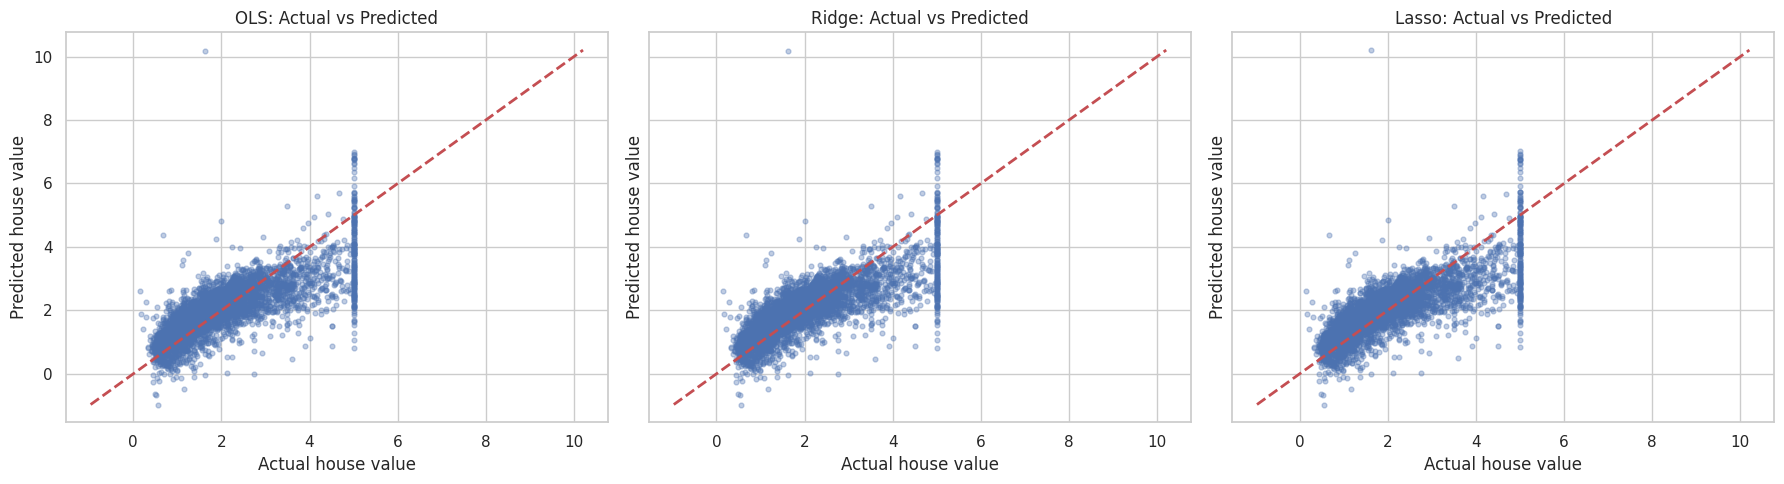

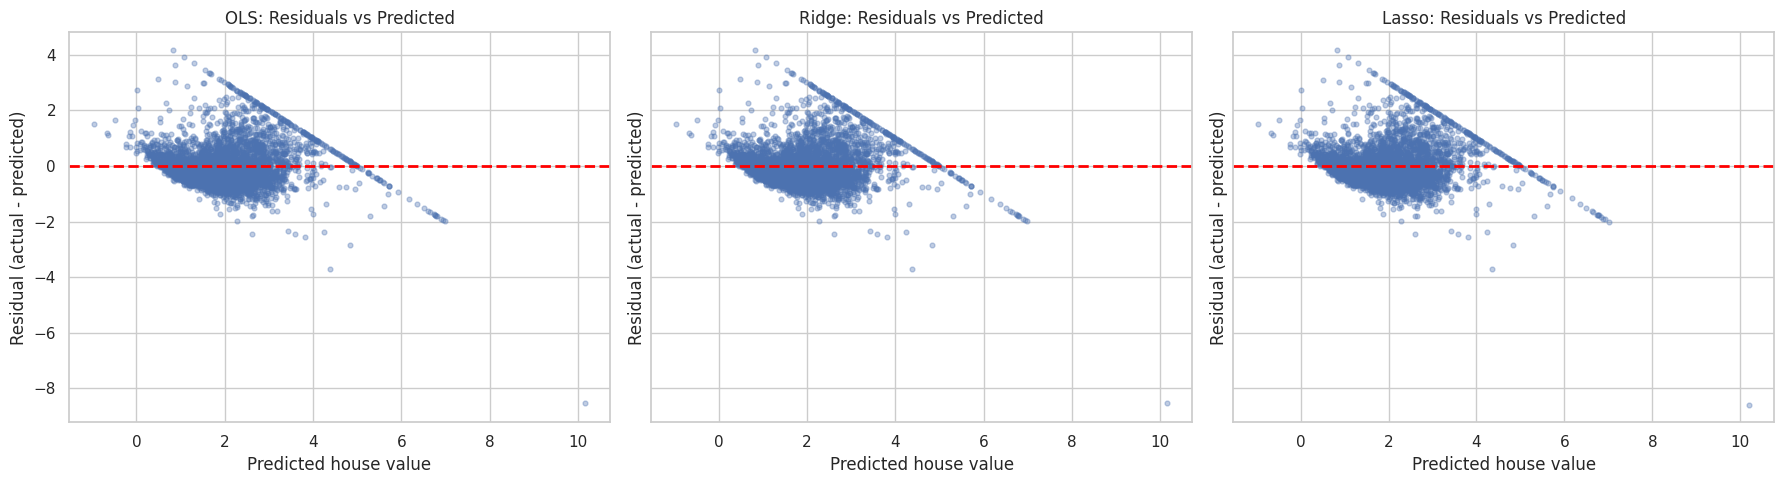

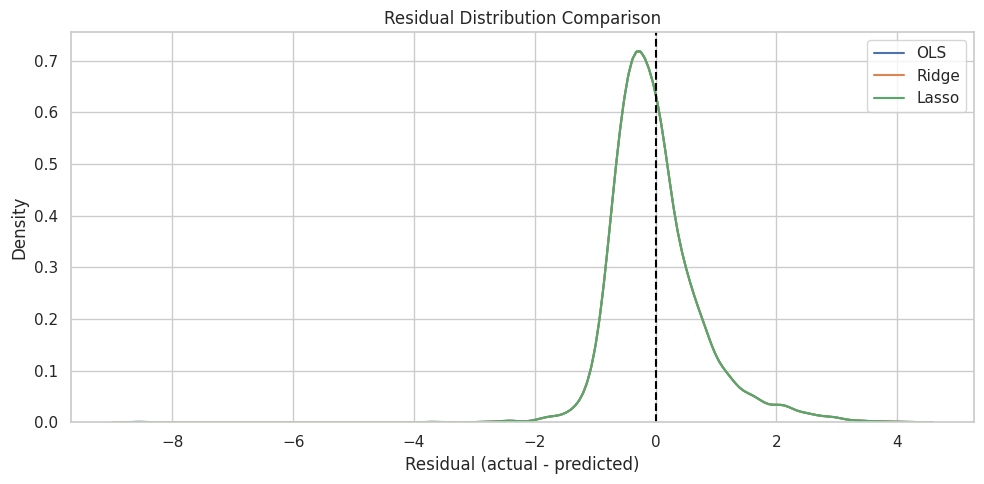

In [14]:
# Predicted vs. actual plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

min_value = min(y_test.min(), *(pred.min() for pred in predictions.values()))
max_value = max(y_test.max(), *(pred.max() for pred in predictions.values()))

for ax, (model_name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.35, s=12)
    ax.plot([min_value, max_value], [min_value, max_value], "r--", linewidth=2)
    ax.set_title(f"{model_name}: Actual vs Predicted")
    ax.set_xlabel("Actual house value")
    ax.set_ylabel("Predicted house value")

plt.tight_layout()
plt.show()

# Residuals vs. predicted values
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, (model_name, y_pred) in zip(axes, predictions.items()):
    residuals = y_test.to_numpy() - y_pred
    ax.scatter(y_pred, residuals, alpha=0.35, s=12)
    ax.axhline(0, color="red", linestyle="--", linewidth=2)
    ax.set_title(f"{model_name}: Residuals vs Predicted")
    ax.set_xlabel("Predicted house value")
    ax.set_ylabel("Residual (actual - predicted)")

plt.tight_layout()
plt.show()

# Residual distributions
plt.figure(figsize=(10, 5))
for model_name, y_pred in predictions.items():
    residuals = y_test.to_numpy() - y_pred
    sns.kdeplot(residuals, label=model_name, fill=False)
plt.axvline(0, color="black", linestyle="--")
plt.title("Residual Distribution Comparison")
plt.xlabel("Residual (actual - predicted)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
print("FINAL MODEL COMPARISON")
display(metrics_df.sort_values("RMSE").round(4))

print("\\nCONCLUSION")
print(
    f"By test RMSE, {best_by_rmse} performed best "
    f"(RMSE={metrics_df.loc[best_by_rmse, 'RMSE']:.4f}, "
    f"MAE={metrics_df.loc[best_by_rmse, 'MAE']:.4f}, "
    f"R²={metrics_df.loc[best_by_rmse, 'R2']:.4f})."
)
print(
    f"By test MAE, {best_by_mae} performed best; "
    f"by test R², {best_by_r2} performed best."
)
print(
    "Ridge applies L2 regularization, shrinking coefficients to help control "
    "instability from correlated features. Lasso applies L1 regularization and "
    f"set approximately {lasso_zero_count} coefficient(s) to zero in this run."
)
print(
    "Use the predicted-versus-actual and residual plots to check for systematic "
    "errors, curvature, unequal residual spread, and outliers. The best model "
    "should be selected using the metrics together with these diagnostic plots."
)

# Optional: save the test-set predictions and metrics for reporting.
results_df = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "OLS_Predicted": ols_predictions,
    "Ridge_Predicted": ridge_predictions,
    "Lasso_Predicted": lasso_predictions
})
results_df.to_csv("california_housing_test_predictions.csv", index=False)
metrics_df.to_csv("california_housing_model_metrics.csv")

print("\\nSaved:")
print("- california_housing_test_predictions.csv")
print("- california_housing_model_metrics.csv")

FINAL MODEL COMPARISON


,RMSE,MAE,R2
Model,,,
Ridge,0.7418,0.5339,0.5801
OLS,0.7418,0.5339,0.5801
Lasso,0.7418,0.5338,0.5801


\nCONCLUSION
By test RMSE, Ridge performed best (RMSE=0.7418, MAE=0.5339, R²=0.5801).
By test MAE, Lasso performed best; by test R², Ridge performed best.
Ridge applies L2 regularization, shrinking coefficients to help control instability from correlated features. Lasso applies L1 regularization and set approximately 0 coefficient(s) to zero in this run.
Use the predicted-versus-actual and residual plots to check for systematic errors, curvature, unequal residual spread, and outliers. The best model should be selected using the metrics together with these diagnostic plots.
\nSaved:
- california_housing_test_predictions.csv
- california_housing_model_metrics.csv
